Problem Statement

A financial institution wants to automate its loan approval process. The company wants to identify whether a customer's loan application should be approved or rejected based on the customer's personal, financial, employment, credit-history, and property-related information.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier


In [ ]:
df=pd.read_csv("train.csv")
print(df.head())

    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

In [ ]:
df.shape

(614, 13)

In [ ]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [ ]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [ ]:
# missing value percentage
missing=df.isnull().sum()
miss_per=(missing/len(df))*100
miss_table=pd.DataFrame({'Missing Values':missing,'Percentage':miss_per})
print(miss_table)

                   Missing Values  Percentage
Loan_ID                         0    0.000000
Gender                         13    2.117264
Married                         3    0.488599
Dependents                     15    2.442997
Education                       0    0.000000
Self_Employed                  32    5.211726
ApplicantIncome                 0    0.000000
CoapplicantIncome               0    0.000000
LoanAmount                     22    3.583062
Loan_Amount_Term               14    2.280130
Credit_History                 50    8.143322
Property_Area                   0    0.000000
Loan_Status                     0    0.000000


In [ ]:
#dupalicate row
print("dupalicated row:",df.duplicated().sum())

dupalicated row: 0


In [ ]:
# check unique values
for column in df.columns:
    print(df[column].unique())

<StringArray>
['LP001002', 'LP001003', 'LP001005', 'LP001006', 'LP001008', 'LP001011',
 'LP001013', 'LP001014', 'LP001018', 'LP001020',
 ...
 'LP002959', 'LP002960', 'LP002961', 'LP002964', 'LP002974', 'LP002978',
 'LP002979', 'LP002983', 'LP002984', 'LP002990']
Length: 614, dtype: str
<StringArray>
['Male', 'Female', nan]
Length: 3, dtype: str
<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
<StringArray>
['0', '1', '2', '3+', nan]
Length: 5, dtype: str
<StringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str
<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
[ 5849  4583  3000  2583  6000  5417  2333  3036  4006 12841  3200  2500
  3073  1853  1299  4950  3596  3510  4887  2600  7660  5955  3365  3717
  9560  2799  4226  1442  3750  4166  3167  4692  3500 12500  2275  1828
  3667  3748  3600  1800  2400  3941  4695  3410  5649  5821  2645  4000
  1928  3086  4230  4616 11500  2708  2132  3366  8080  3357  3029  2609
  4945  5726 10750  7100  4300  3208  1875  4755  

In [ ]:
print(df["Loan_Status"].value_counts())

Loan_Status
Y    422
N    192
Name: count, dtype: int64


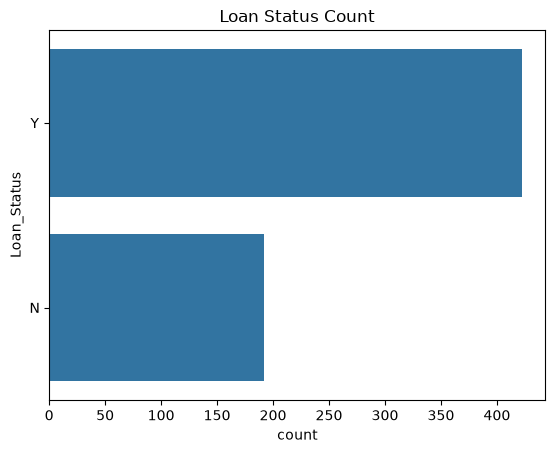

In [ ]:
sns.countplot(df["Loan_Status"])
plt.title("Loan Status Count")
plt.show()

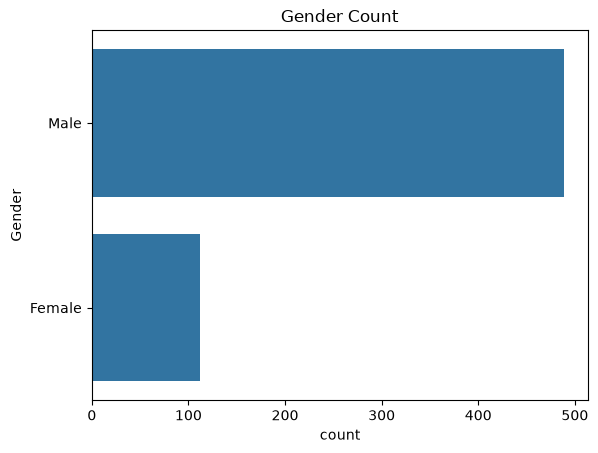

In [ ]:
sns.countplot(df["Gender"])
plt.title("Gender Count")
plt.show()

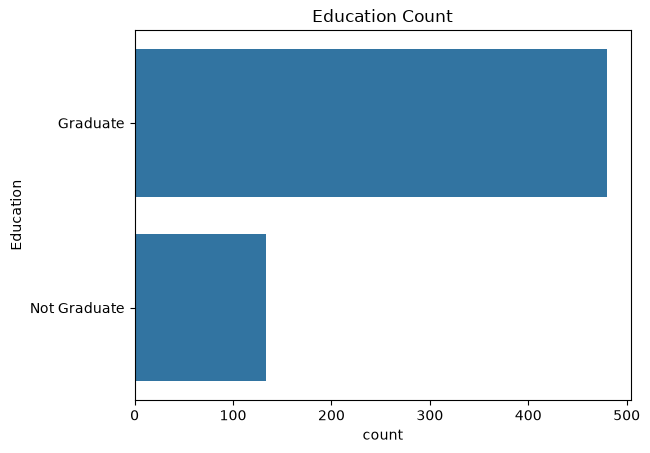

In [ ]:
sns.countplot(df['Education'])
plt.title("Education Count")
plt.show()

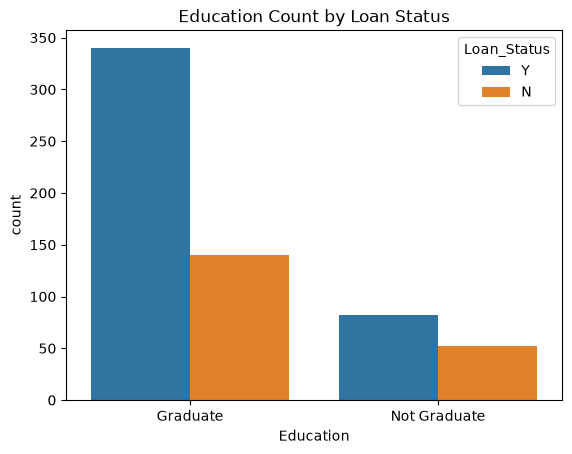

In [ ]:
sns.countplot(x='Education',hue='Loan_Status',data=df)
plt.title("Education Count by Loan Status")
plt.show()

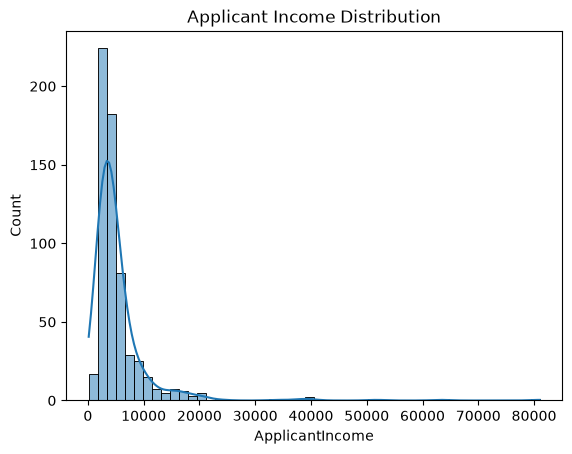

In [ ]:
#Applicant Income Distribution
sns.histplot(df['ApplicantIncome'],kde=True)
plt.title("Applicant Income Distribution")
plt.show()

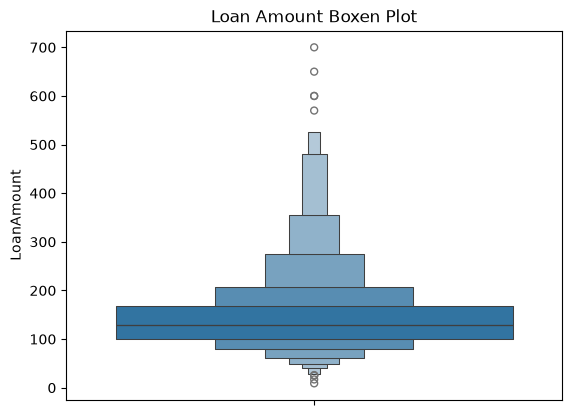

In [ ]:
# outlier
sns.boxenplot(df['LoanAmount'])
plt.title("Loan Amount Boxen Plot")
plt.show()

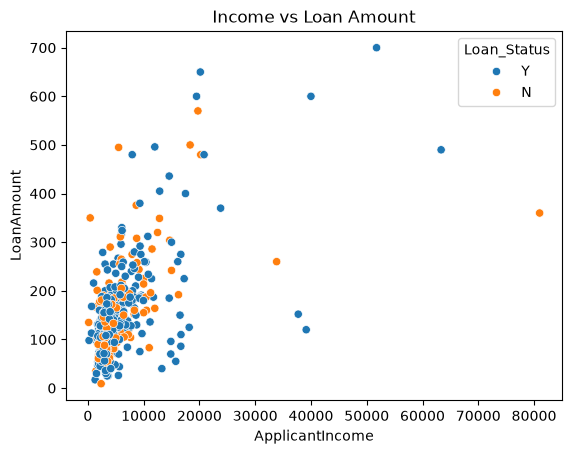

In [ ]:
#Income vs Loan Amount
sns.scatterplot(x='ApplicantIncome',y='LoanAmount',hue='Loan_Status',data=df)
plt.title("Income vs Loan Amount")
plt.show()

In [ ]:
df_clean=df.copy()

In [ ]:
df_clean.drop("Loan_ID",axis=1,inplace=True)

In [ ]:
print(df_clean.columns)

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')


In [ ]:
# handeling missing value
print(df_clean.isnull().sum())

Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [ ]:
# Fill Categorical Missing Values
columns=["Gender","Married","Dependents","Self_Employed","Credit_History"]
for i in columns:
    df_clean[i]=df_clean[i].fillna(df_clean[i].mode()[0])

In [ ]:
# Fill Numerical Missing Values
num_columns=["LoanAmount","Loan_Amount_Term"]
for i in num_columns:
    df_clean[i]=df_clean[i].fillna(df_clean[i].median())

In [ ]:
df_clean.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [ ]:
print("Duplicates:", df_clean.duplicated().sum())

Duplicates: 0


In [ ]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    str    
 1   Married            614 non-null    str    
 2   Dependents         614 non-null    str    
 3   Education          614 non-null    str    
 4   Self_Employed      614 non-null    str    
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         614 non-null    float64
 8   Loan_Amount_Term   614 non-null    float64
 9   Credit_History     614 non-null    float64
 10  Property_Area      614 non-null    str    
 11  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(7)
memory usage: 57.7 KB


In [ ]:
# Check Dependents
df_clean['Dependents']=df_clean['Dependents'].replace('3+',3)
# convert categorical to numerical
df_clean['Dependents']=pd.to_numeric(df_clean['Dependents'])
print(df_clean["Dependents"].unique())

[0 1 2 3]


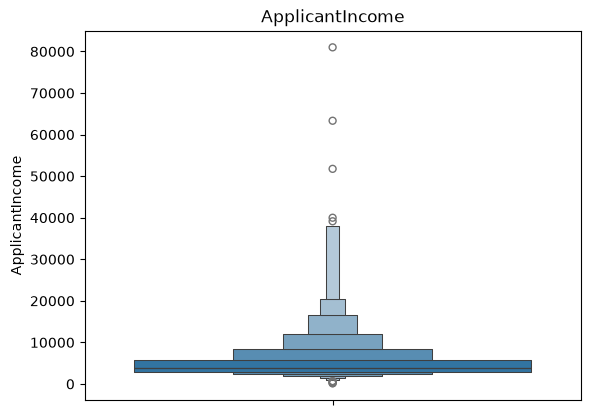

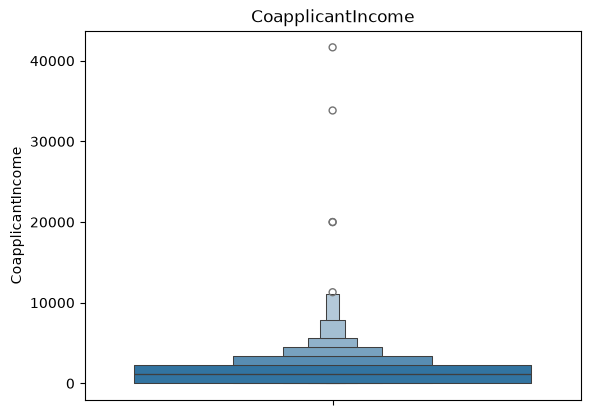

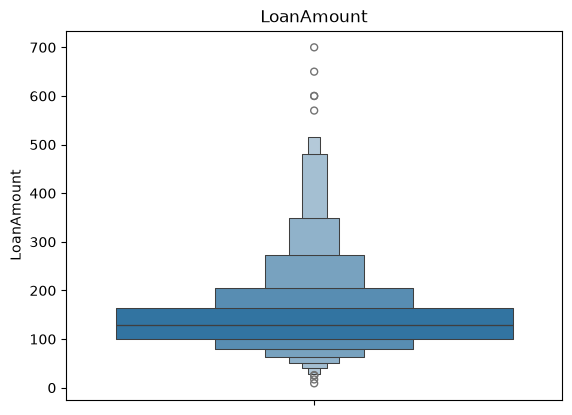

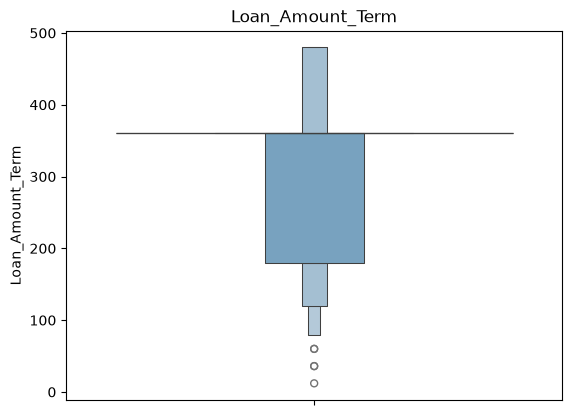

In [ ]:
# check outliers
numeric_cols=['ApplicantIncome','CoapplicantIncome','LoanAmount','Loan_Amount_Term']
for i in numeric_cols:
    sns.boxenplot(df_clean[i])
    plt.title(i)
    plt.show()

In [ ]:
# Feature Engineering — Total Income
df_clean['TotalIncome'] = df_clean['ApplicantIncome'] + df_clean['CoapplicantIncome']
print(
    df_clean[
        ["ApplicantIncome",
         "CoapplicantIncome",
         "TotalIncome"]
    ].head()
)

   ApplicantIncome  CoapplicantIncome  TotalIncome
0             5849                0.0       5849.0
1             4583             1508.0       6091.0
2             3000                0.0       3000.0
3             2583             2358.0       4941.0
4             6000                0.0       6000.0


In [ ]:
# Feature Engineering — Total Income Log

# Income is usually highly right-skewed.

# We can reduce the effect of extreme values using log1p()

df_clean["TotalIncome_log"] = np.log1p(
    df_clean["TotalIncome"]
)

In [ ]:
print(df_clean.head())
print(df_clean.shape)

  Gender Married  Dependents     Education Self_Employed  ApplicantIncome  \
0   Male      No           0      Graduate            No             5849   
1   Male     Yes           1      Graduate            No             4583   
2   Male     Yes           0      Graduate           Yes             3000   
3   Male     Yes           0  Not Graduate            No             2583   
4   Male      No           0      Graduate            No             6000   

   CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  \
0                0.0       128.0             360.0             1.0   
1             1508.0       128.0             360.0             1.0   
2                0.0        66.0             360.0             1.0   
3             2358.0       120.0             360.0             1.0   
4                0.0       141.0             360.0             1.0   

  Property_Area Loan_Status  TotalIncome  TotalIncome_log  
0         Urban           Y       5849.0         8.67419

In [ ]:
print(df_clean.isnull().sum().sum())

0


In [ ]:
# separete x and y
X=df_clean.drop("Loan_Status",axis=1)
y=df_clean["Loan_Status"]

In [ ]:
print(X.head())
print(y.head())

  Gender Married  Dependents     Education Self_Employed  ApplicantIncome  \
0   Male      No           0      Graduate            No             5849   
1   Male     Yes           1      Graduate            No             4583   
2   Male     Yes           0      Graduate           Yes             3000   
3   Male     Yes           0  Not Graduate            No             2583   
4   Male      No           0      Graduate            No             6000   

   CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  \
0                0.0       128.0             360.0             1.0   
1             1508.0       128.0             360.0             1.0   
2                0.0        66.0             360.0             1.0   
3             2358.0       120.0             360.0             1.0   
4                0.0       141.0             360.0             1.0   

  Property_Area  TotalIncome  TotalIncome_log  
0         Urban       5849.0         8.674197  
1         Rural     

In [ ]:
#encoding
X=pd.get_dummies(X,drop_first=True)
print(X.head())

   Dependents  ApplicantIncome  CoapplicantIncome  LoanAmount  \
0           0             5849                0.0       128.0   
1           1             4583             1508.0       128.0   
2           0             3000                0.0        66.0   
3           0             2583             2358.0       120.0   
4           0             6000                0.0       141.0   

   Loan_Amount_Term  Credit_History  TotalIncome  TotalIncome_log  \
0             360.0             1.0       5849.0         8.674197   
1             360.0             1.0       6091.0         8.714732   
2             360.0             1.0       3000.0         8.006701   
3             360.0             1.0       4941.0         8.505525   
4             360.0             1.0       6000.0         8.699681   

   Gender_Male  Married_Yes  Education_Not Graduate  Self_Employed_Yes  \
0         True        False                   False              False   
1         True         True                   

In [ ]:
y = y.map({
    "Y": 1,
    "N": 0
})
print(y.head())

0    1
1    0
2    1
3    1
4    1
Name: Loan_Status, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (491, 14)
X_test: (123, 14)
y_train: (491,)
y_test: (123,)


In [ ]:
scaler = StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [ ]:
# Logistic Regression Model
lr=LogisticRegression()
lr.fit(X_train_scaled,y_train)
y_pred_lr=lr.predict(X_test_scaled)
print("LogisticRegression accuracy:",accuracy_score(y_test,y_pred_lr))
print(classification_report(y_test,y_pred_lr))

LogisticRegression accuracy: 0.8536585365853658
              precision    recall  f1-score   support

           0       0.92      0.58      0.71        38
           1       0.84      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.88      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123



In [ ]:
#KNN Model
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled,y_train)
y_pred_knn=knn.predict(X_test_scaled)
print("KNN accuracy:",accuracy_score(y_test,y_pred_knn))
print(classification_report(y_test,y_pred_knn))

KNN accuracy: 0.8292682926829268
              precision    recall  f1-score   support

           0       0.81      0.58      0.68        38
           1       0.83      0.94      0.88        85

    accuracy                           0.83       123
   macro avg       0.82      0.76      0.78       123
weighted avg       0.83      0.83      0.82       123



In [ ]:
# decision tree model
dt=DecisionTreeClassifier(random_state=42)
dt.fit(X_train_scaled,y_train)
y_pred_df=dt.predict(X_test_scaled)
print("Decision Tree accuracy:",accuracy_score(y_test,y_pred_df))
print(classification_report(y_test,y_pred_df))

Decision Tree accuracy: 0.7398373983739838
              precision    recall  f1-score   support

           0       0.57      0.68      0.62        38
           1       0.84      0.76      0.80        85

    accuracy                           0.74       123
   macro avg       0.70      0.72      0.71       123
weighted avg       0.76      0.74      0.75       123



In [ ]:
# random forest model
rf=RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled,y_train)
y_pred_rf=rf.predict(X_test_scaled)
print("Random Forest accuracy:",accuracy_score(y_test,y_pred_rf))
print(classification_report(y_test,y_pred_rf))

Random Forest accuracy: 0.8373983739837398
              precision    recall  f1-score   support

           0       0.76      0.68      0.72        38
           1       0.87      0.91      0.89        85

    accuracy                           0.84       123
   macro avg       0.81      0.80      0.80       123
weighted avg       0.83      0.84      0.83       123



In [ ]:
# XGBoost model
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
xgb.fit(X_train_scaled, y_train)
y_pred_xgb = xgb.predict(X_test_scaled)
print("XGBoost accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

XGBoost accuracy: 0.8373983739837398
              precision    recall  f1-score   support

           0       0.85      0.58      0.69        38
           1       0.84      0.95      0.89        85

    accuracy                           0.84       123
   macro avg       0.84      0.77      0.79       123
weighted avg       0.84      0.84      0.83       123



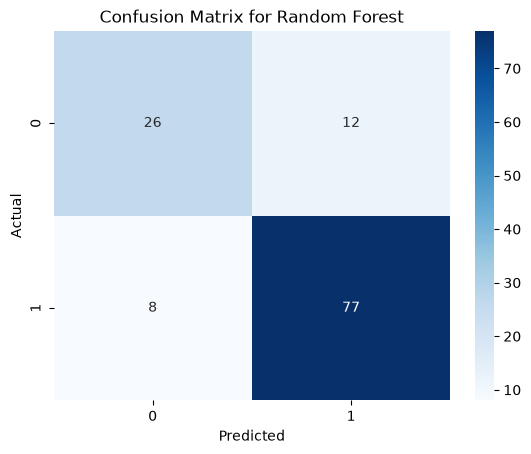

In [ ]:
# confusion matrix for rf

cm=confusion_matrix(y_test,y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix for Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# feature importance for Random Forest

importance=importance.sort_values(
    "Importance",
    ascending=False
)
print(importance)

                    Feature  Importance
5            Credit_History    0.218510
1           ApplicantIncome    0.136892
7           TotalIncome_log    0.131603
6               TotalIncome    0.126409
3                LoanAmount    0.124150
2         CoapplicantIncome    0.072956
0                Dependents    0.043702
4          Loan_Amount_Term    0.037595
12  Property_Area_Semiurban    0.021792
10   Education_Not Graduate    0.021133
9               Married_Yes    0.018160
13      Property_Area_Urban    0.016848
11        Self_Employed_Yes    0.015489
8               Gender_Male    0.014761


In [ ]:
# hyperparameter tunnig
rf_params = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 7, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
rf_grid.fit(
    X_train,
    y_train
)
print("Best Random Forest Parameters:")

print(
    rf_grid.best_params_
)

print("Best Random Forest CV Score:")

print(
    rf_grid.best_score_
)


Best Random Forest Parameters:
{'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 50}
Best Random Forest CV Score:
0.8024531024531024


In [ ]:
best_rf = rf_grid.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)

print("Tuned Random Forest Accuracy:")

print(
    accuracy_score(
        y_test,
        y_pred_best_rf
    )
)

print(
    classification_report(
        y_test,
        y_pred_best_rf
    )
)

Tuned Random Forest Accuracy:
0.8536585365853658
              precision    recall  f1-score   support

           0       0.88      0.61      0.72        38
           1       0.85      0.96      0.90        85

    accuracy                           0.85       123
   macro avg       0.86      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123



In [ ]:
#Before vs After Random Forest

rf_before = accuracy_score(
    y_test,
    y_pred_rf
)

rf_after = accuracy_score(
    y_test,
    y_pred_best_rf
)

print("Random Forest Before Tuning:", rf_before)
print("Random Forest After Tuning:", rf_after)

Random Forest Before Tuning: 0.8373983739837398
Random Forest After Tuning: 0.8536585365853658


In [ ]:
#Predict a New Customer

new_customer = pd.DataFrame({
    "Gender": ["Male"],
    "Married": ["Yes"],
    "Dependents": [1],
    "Education": ["Graduate"],
    "Self_Employed": ["No"],
    "ApplicantIncome": [5000],
    "CoapplicantIncome": [2000],
    "LoanAmount": [150],
    "Loan_Amount_Term": [360],
    "Credit_History": [1],
    "Property_Area": ["Urban"],
    "TotalIncome": [7000],
    "TotalIncome_log": [np.log1p(7000)]
})
new_customer = pd.get_dummies(
    new_customer,
    drop_first=True
)
new_customer = new_customer.reindex(
    columns=X.columns,
    fill_value=0
)
prediction = best_rf.predict(
    new_customer
)

print("Loan Prediction:", prediction[0])

if prediction[0] == 1:
    print("Loan Approved")
else:
    print("Loan Rejected")


Loan Prediction: 1
Loan Approved
